# Laboratorio: Conectando una protoboard con la menor cantidad de cable

In [10]:
nombre_estudiante = "Juan José Mican, Alejandro Gil León, Mariana Shenoa Castiblanco, Thaliana Rocio Sierra"
id_estudiante = 1000116549, 1000115165, 1000112473, 1000116534

## 1) Descripción del problema **[1 pts]**

Se necesita conectar siete componentes ubicados en diferentes posiciones de una protoboard, utilizando la menor longitud total de cable posible. Cada componente se representa mediante un vértice y cada conexión posible mediante una arista cuyo peso corresponde a la distancia Manhattan entre las posiciones.

Se busca un **Árbol de Expansión Mínima (MST)**. Para encontrarlo se implementa **Kruskal**, que ordena las aristas por peso y selecciona aquellas que no formen ciclos. Después se cambia el Buzzer de H6 a J20 y se recalcula el MST para comparar la longitud total.

## 2) Requerimientos **[2 pts]**

### Requerimientos funcionales

- **RF01:** Permitir definir la protoboard con 30 columnas y 10 filas, identificadas de A a J.
- **RF02:** Registrar los siete componentes con su identificador, nombre y posición.
- **RF03:** Representar gráficamente la protoboard y ubicar cada componente en su posición.
- **RF04:** Calcular automáticamente la distancia entre cada pareja de componentes, sumando la diferencia entre sus columnas y la diferencia entre sus filas.
- **RF05:** Construir el grafo con los siete vértices y las 21 conexiones posibles.
- **RF06:** Mostrar todas las conexiones posibles con el peso calculado para cada una.
- **RF07:** Ordenar las conexiones de menor a mayor peso e implementar el algoritmo de Kruskal.
- **RF08:** Evitar la formación de ciclos al seleccionar las conexiones.
- **RF09:** Mostrar el árbol final con seis conexiones y calcular la longitud total del cable.
- **RF10:** Cambiar la posición del Buzzer de H6 a J20 y recalcular las conexiones y el árbol.

### Requerimientos no funcionales

- **RNF01:** El código debe estar organizado en funciones, ser legible y contar con comentarios que expliquen su funcionamiento.
- **RNF02:** Las gráficas deben permitir identificar claramente las filas, columnas y componentes.
- **RNF03:** Los cálculos deben realizarse automáticamente a partir de las posiciones registradas.
- **RNF04:** No utilizar librerías que calculen directamente el árbol de expansión mínima.
- **RNF05:** El Notebook debe poder ejecutarse de principio a fin sin errores.

## 3) Historias de usuario **[2 pts]**

**HU01 — Ubicar componentes**  
Como encargado del montaje, quiero visualizar los componentes en la protoboard según sus coordenadas, para identificar su distribución inicial.

**Criterios de aceptación:** se muestran filas A–J, columnas 1–30 y cada componente aparece con su identificador en la posición correcta.

**HU02 — Calcular conexiones**  
Como encargado del montaje, quiero conocer la distancia entre cada pareja de componentes, para saber cuánto cable requiere cada conexión posible.

**Criterios de aceptación:** se calculan las 21 parejas y cada peso se obtiene mediante la distancia Manhattan.

**HU03 — Encontrar el cableado mínimo**  
Como encargado del montaje, quiero obtener un MST mediante Kruskal, para conectar todos los componentes con la menor longitud total.

**Criterios de aceptación:** las aristas se ordenan por peso, no se agregan ciclos y el resultado contiene exactamente 6 conexiones.

**HU04 — Actualizar la distribución**  
Como encargado del montaje, quiero cambiar la posición del Buzzer y recalcular el árbol, para conocer cómo afecta el cambio a la cantidad de cable.

**Criterios de aceptación:** el Buzzer cambia de H6 a J20, se recalculan distancias y MST, y se comparan las longitudes.

## 4) Diagramas de flujo **[5 pts]**

El proceso comienza definiendo los componentes y sus coordenadas. Se generan todas las parejas, se calcula el peso de cada arista y se ordenan las conexiones. Kruskal recorre las aristas y solo agrega una conexión cuando sus extremos pertenecen a conjuntos diferentes. Termina cuando se seleccionan \(n-1\) aristas.

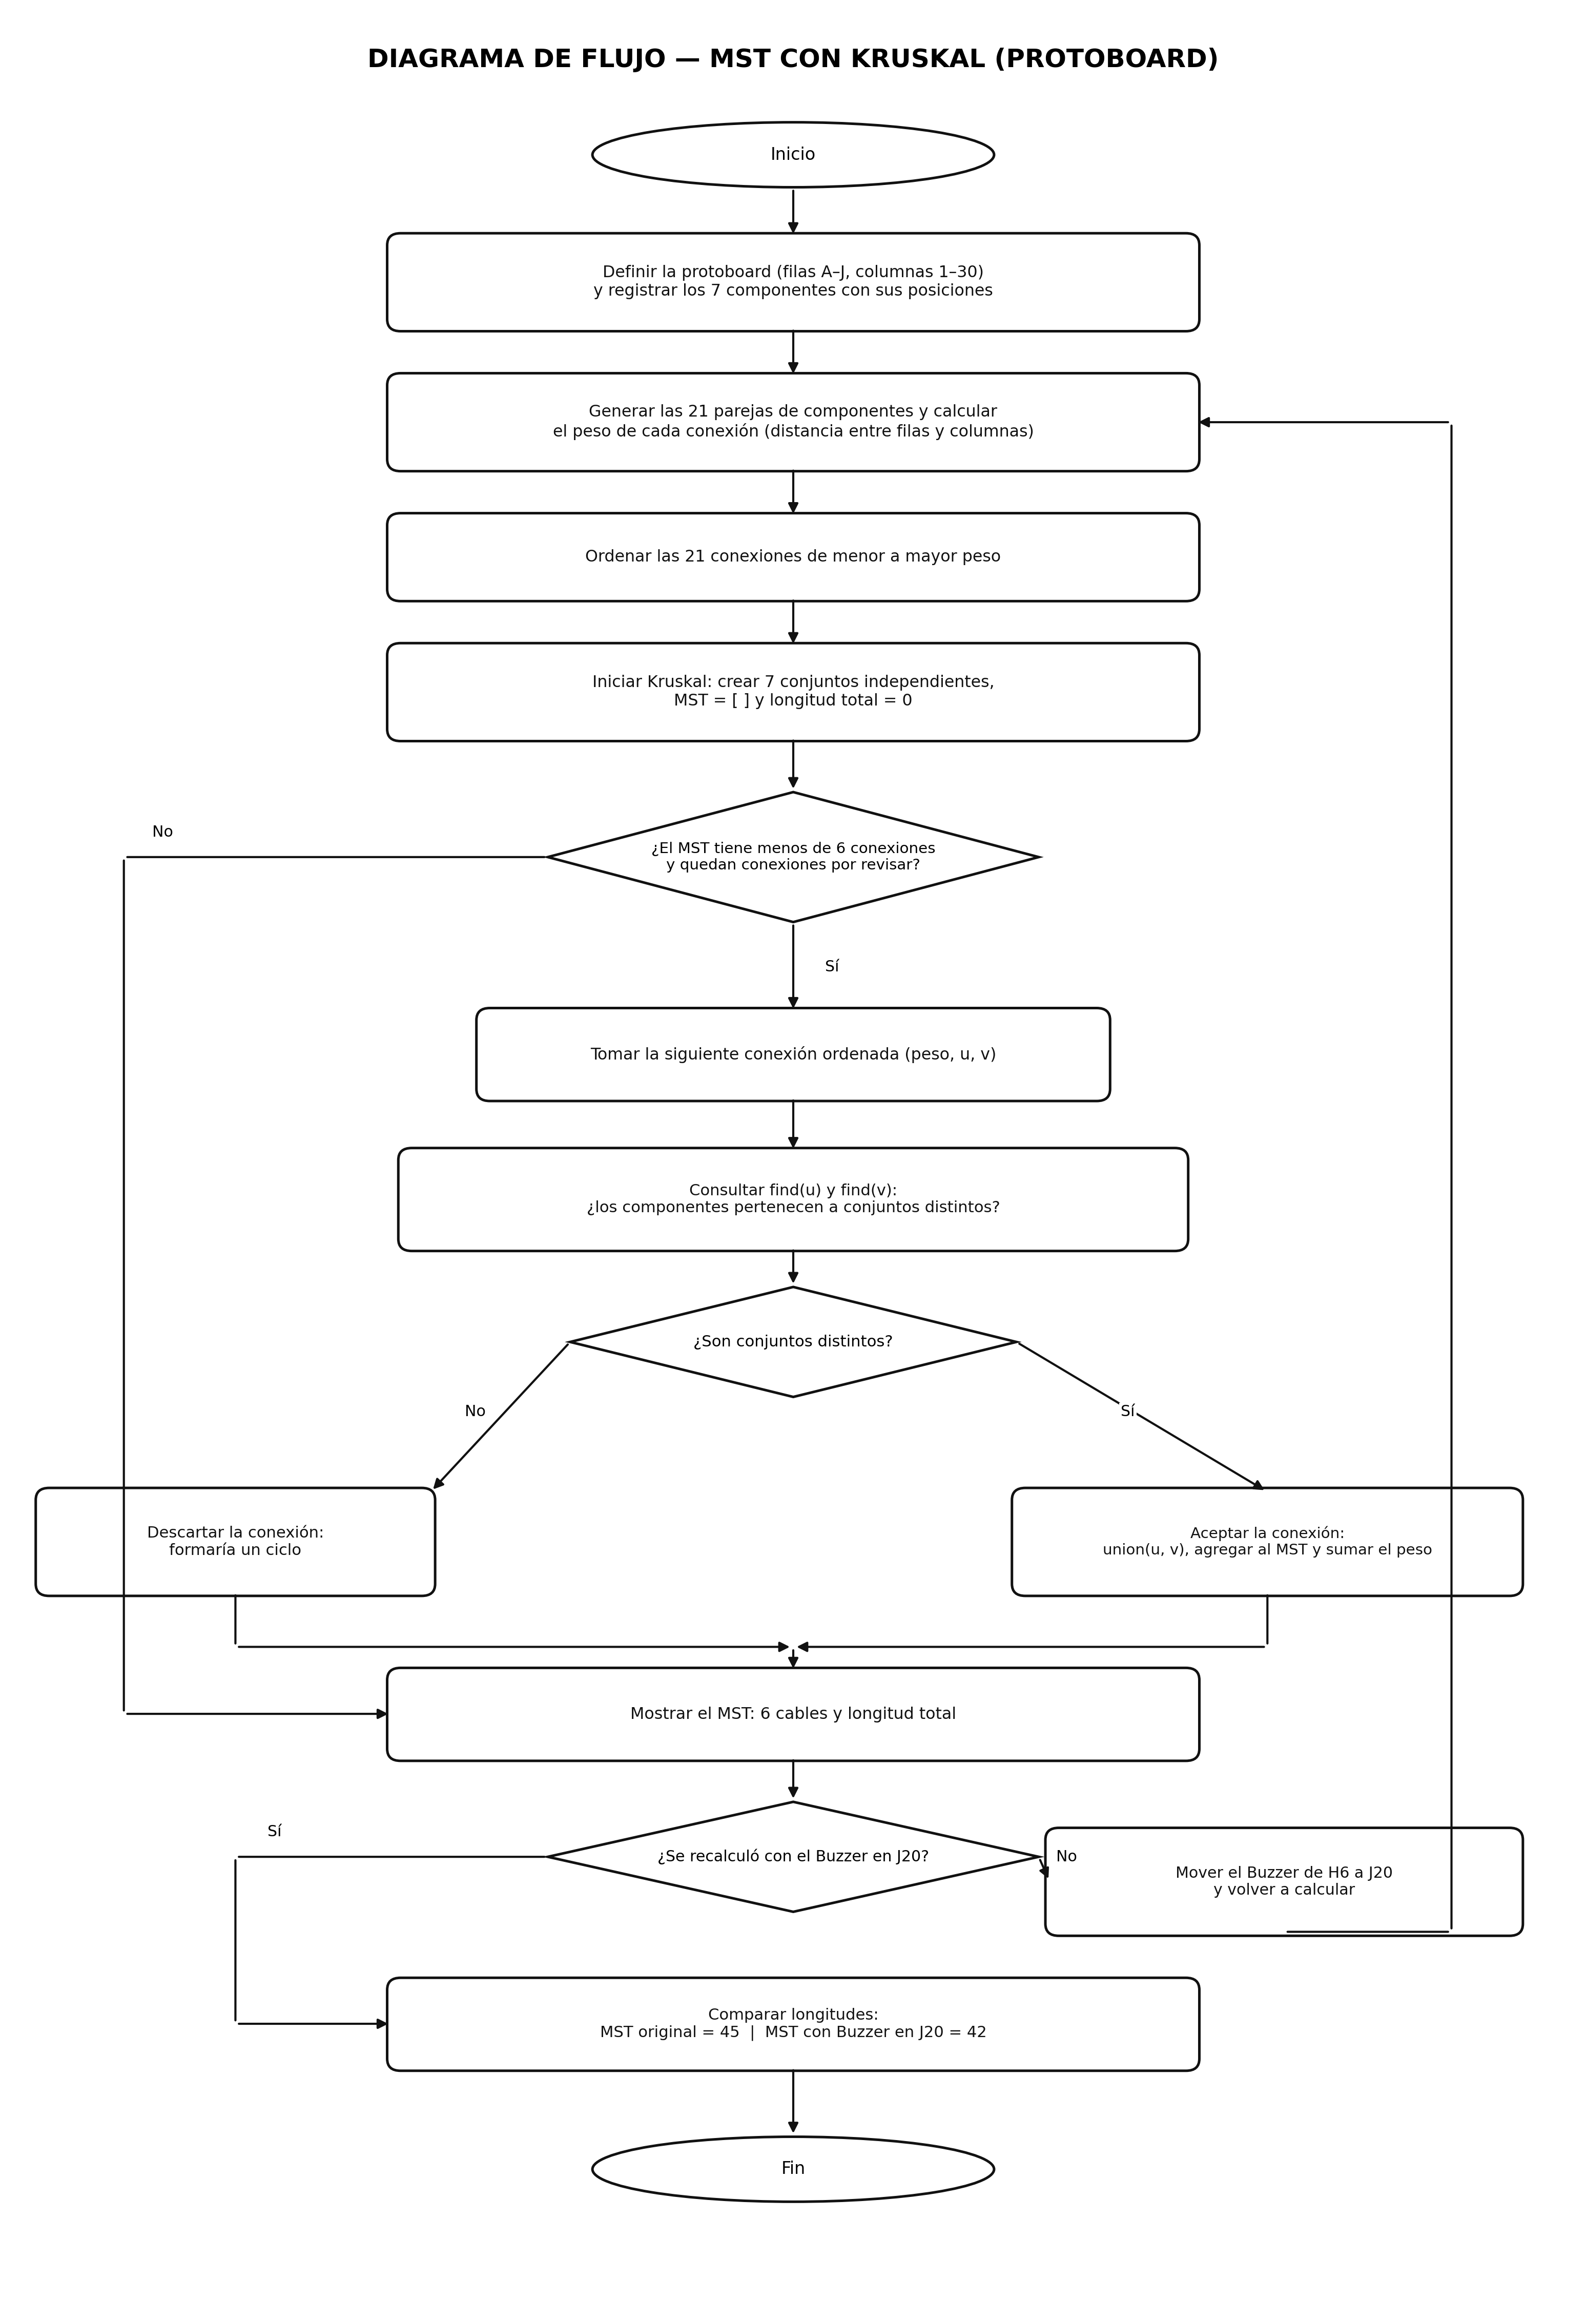

## 5) Análisis de complejidad **[15 pts]**

**Justificación**

Para $n$ componentes se genera una conexión entre cada pareja distinta:

$$E=\frac{n(n-1)}{2}$$

Generar las aristas cuesta $O(n^2)$. Kruskal ordena las $E$ aristas, lo que cuesta $O(E\log E)$. Para detectar ciclos se utiliza *Union-Find*, cuyas operaciones cuestan amortizadamente $O(\alpha(n))$.

**Función de tiempo**

$$T(n)=c_1\frac{n(n-1)}{2}+c_2E\log E+c_3E\,\alpha(n)$$

El término dominante es el ordenamiento. Como $E=\frac{n(n-1)}{2}$, la complejidad es:

$$T(n)=O(n^2\log n)$$

**Mejor y peor caso:** en esta implementación se generan y ordenan todas las aristas antes de ejecutar Kruskal. Por ello, tanto el mejor como el peor caso mantienen complejidad asintótica $O(n^2\log n)$. Cambia la cantidad de aristas recorridas y descartadas por formar ciclos.

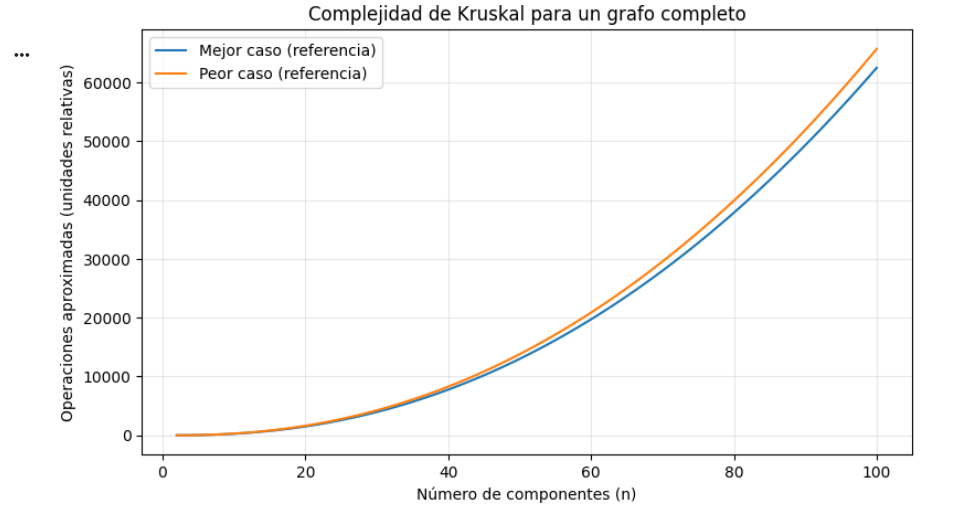

## 6) Código funcional **[15 pts]**


In [11]:
import matplotlib.pyplot as plt
from itertools import combinations

ROWS = {letter: index for index, letter in enumerate("ABCDEFGHIJ", start=1)}
NUM_COLUMNS = 30

initial_components = {
    "F": {"nombre": "Fuente de alimentación", "fila": "A", "columna": 3},
    "L": {"nombre": "LED", "fila": "C", "columna": 8},
    "S": {"nombre": "Sensor", "fila": "B", "columna": 16},
    "P": {"nombre": "Pulsador", "fila": "D", "columna": 24},
    "B": {"nombre": "Buzzer", "fila": "H", "columna": 6},
    "R": {"nombre": "Potenciómetro", "fila": "I", "columna": 15},
    "M": {"nombre": "Microcontrolador", "fila": "G", "columna": 25},
}


def calculate_distance(component1, component2):
    row1 = ROWS[component1["fila"]]
    row2 = ROWS[component2["fila"]]
    col1 = component1["columna"]
    col2 = component2["columna"]
    return abs(col1 - col2) + abs(row1 - row2)


def build_edges(components):
    edges = []
    for u, v in combinations(components.keys(), 2):
        weight = calculate_distance(components[u], components[v])
        edges.append((weight, u, v))
    return edges


class UnionFind:
    def __init__(self, vertices):
        self.parent = {vertex: vertex for vertex in vertices}
        self.rank = {vertex: 0 for vertex in vertices}

    def find(self, vertex):
        if self.parent[vertex] != vertex:
            self.parent[vertex] = self.find(self.parent[vertex])
        return self.parent[vertex]


    def union(self, u, v):
        root_u = self.find(u)
        root_v = self.find(v)

        if root_u == root_v:
            return False

        if self.rank[root_u] < self.rank[root_v]:
            self.parent[root_u] = root_v
        elif self.rank[root_u] > self.rank[root_v]:
            self.parent[root_v] = root_u
        else:
            self.parent[root_v] = root_u
            self.rank[root_u] += 1
        return True


def kruskal(components):
    edges = build_edges(components)
    sorted_edges = sorted(edges)
    sets = UnionFind(components.keys())
    mst = []
    record = []

    for weight, u, v in sorted_edges:
        if len(mst) == len(components) - 1:
            break
        if sets.union(u, v):
            mst.append((weight, u, v))
            record.append((weight, u, v, True))
        else:
            record.append((weight, u, v, False))

    total_length = sum(weight for weight, _, _ in mst)
    return edges, mst, total_length, record


def move_component(components, identifier, new_row, new_col):
    new_components = {k: data.copy() for k, data in components.items()}
    new_components[identifier]["fila"] = new_row
    new_components[identifier]["columna"] = new_col
    return new_components


def show_connections(edges, title):
    print(title)
    print("-" * 48)
    for weight, u, v in sorted(edges):
        print(f"{u} -------- {weight} -------- {v}")
    print("Cantidad de conexiones posibles:", len(edges))


def show_kruskal_record(record):
    print("Recorrido de Kruskal (aristas ordenadas por peso):")
    for weight, u, v, accepted in record:
        status = "ACEPTADA" if accepted else "descartada (formaría ciclo)"
        print(f"  {u} - {v} = {weight:>2}  ->  {status}")


def show_mst(mst, total_length, title):
    print("\n" + "=" * 12 + f" {title} " + "=" * 12)
    for number, (weight, u, v) in enumerate(mst, start=1):
        print(f"Cable {number}: {u} - {v} = {weight}")
    print("Cantidad de cables:", len(mst))
    print(f"Longitud total de cable: {total_length} unidades")


def wire_route(x1, y1, x2, y2):
    """
    Ruta del cable sobre la cuadrícula, sin diagonales: primero horizontal
    (por la fila del origen) y luego vertical (por la columna del destino).
    Devuelve los puntos del recorrido y la posición del peso, que queda justo
    a la mitad del cable. Largo del recorrido = distancia Manhattan.
    """
    puntos = [(x1, y1), (x2, y1), (x2, y2)]
    horizontal = abs(x2 - x1)
    mitad = (horizontal + abs(y2 - y1)) / 2
    if mitad <= horizontal:
        paso = 1 if x2 >= x1 else -1
        etiqueta = (x1 + paso * mitad, y1)
    else:
        paso = 1 if y2 >= y1 else -1
        etiqueta = (x2, y1 + paso * (mitad - horizontal))
    return puntos, etiqueta


def draw_breadboard(components, connections=None, title="Protoboard",
                    ax=None, wire_color="tab:blue", previous_positions=None):
    own_ax = ax is None
    if own_ax:
        fig, ax = plt.subplots(figsize=(15, 6))

    ax.set_xlim(0.5, NUM_COLUMNS + 0.5)
    ax.set_ylim(10.5, 0.5)
    ax.set_xticks(range(1, NUM_COLUMNS + 1))
    ax.set_yticks(range(1, 11))
    ax.set_yticklabels(list("ABCDEFGHIJ"))
    ax.tick_params(axis="x", labelsize=8)
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel("Columnas")
    ax.set_ylabel("Filas")
    ax.grid(which="major", color="lightgray", linewidth=0.7)

    if previous_positions:
        for identifier, (col, row) in previous_positions.items():
            x0, y0 = col, ROWS[row]
            x1 = components[identifier]["columna"]
            y1 = ROWS[components[identifier]["fila"]]
            ax.scatter(x0, y0, s=180, facecolors="none", edgecolors="gray",
                       linestyles="dashed", zorder=2)
            ax.plot([x0, x1, x1], [y0, y0, y1], color="gray",
                    linestyle="dashed", linewidth=1.2, zorder=1)
            ax.annotate(f"{identifier} antes ({row}{col})", (x0, y0),
                        xytext=(5, -12), textcoords="offset points",
                        fontsize=8, color="gray")

    if connections:
        for weight, u, v in connections:
            x1 = components[u]["columna"]
            y1 = ROWS[components[u]["fila"]]
            x2 = components[v]["columna"]
            y2 = ROWS[components[v]["fila"]]
            puntos, (xe, ye) = wire_route(x1, y1, x2, y2)
            ax.plot([p[0] for p in puntos], [p[1] for p in puntos],
                    linewidth=2.2, alpha=0.8, color=wire_color, zorder=2,
                    solid_joinstyle="miter")
            ax.text(xe, ye, str(weight),
                    fontsize=9, ha="center", va="center", zorder=5,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray"))

    for identifier, data in components.items():
        x = data["columna"]
        y = ROWS[data["fila"]]
        ax.scatter(x, y, s=220, color="gold", edgecolors="black", zorder=3)
        ax.text(x, y, identifier, ha="center", va="center",
                fontsize=9, weight="bold", zorder=6)
        ax.annotate(f"{data['fila']}{x}", (x, y), xytext=(8, 12),
                    textcoords="offset points", fontsize=8, weight="bold")

    ax.set_title(title, fontsize=13, weight="bold", pad=28)
    if own_ax:
        plt.tight_layout()
        plt.show()

### Punto 1 — Construcción visual de la protoboard

Componentes:
  F = Fuente de alimentación   posición A3
  L = LED                      posición C8
  S = Sensor                   posición B16
  P = Pulsador                 posición D24
  B = Buzzer                   posición H6
  R = Potenciómetro            posición I15
  M = Microcontrolador         posición G25


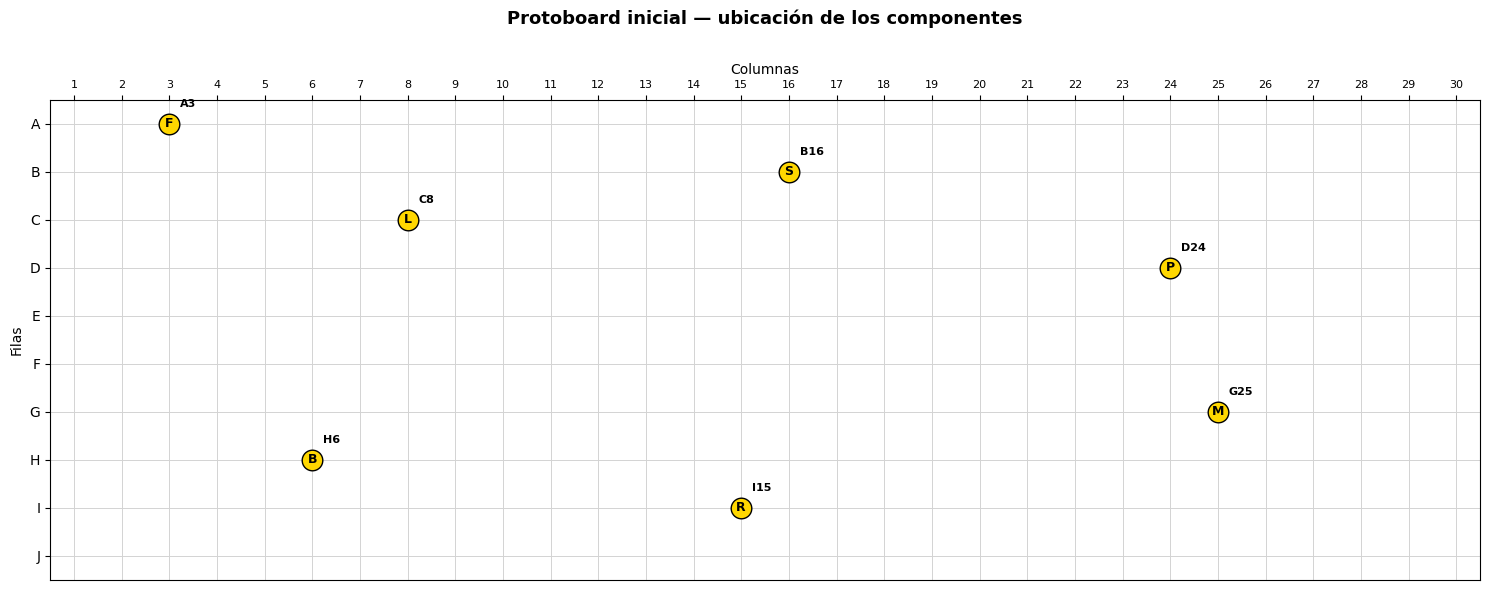

In [12]:
# PUNTO 1
print("Componentes:")
for identifier, data in initial_components.items():
    print(f"  {identifier} = {data['nombre']:<24} posición {data['fila']}{data['columna']}")

draw_breadboard(initial_components,
                title="Protoboard inicial — ubicación de los componentes")

### Puntos 2 y 3 — Construcción del grafo y todas las posibles conexiones

Ejemplo F-L: 7

Todas las conexiones posibles — distribución original
------------------------------------------------
P -------- 4 -------- M
F -------- 7 -------- L
L -------- 7 -------- B
S -------- 8 -------- R
L -------- 9 -------- S
B -------- 10 -------- R
F -------- 10 -------- B
S -------- 10 -------- P
R -------- 12 -------- M
L -------- 13 -------- R
F -------- 14 -------- S
P -------- 14 -------- R
S -------- 14 -------- M
S -------- 16 -------- B
L -------- 17 -------- P
B -------- 20 -------- M
F -------- 20 -------- R
L -------- 21 -------- M
P -------- 22 -------- B
F -------- 24 -------- P
F -------- 28 -------- M
Cantidad de conexiones posibles: 21


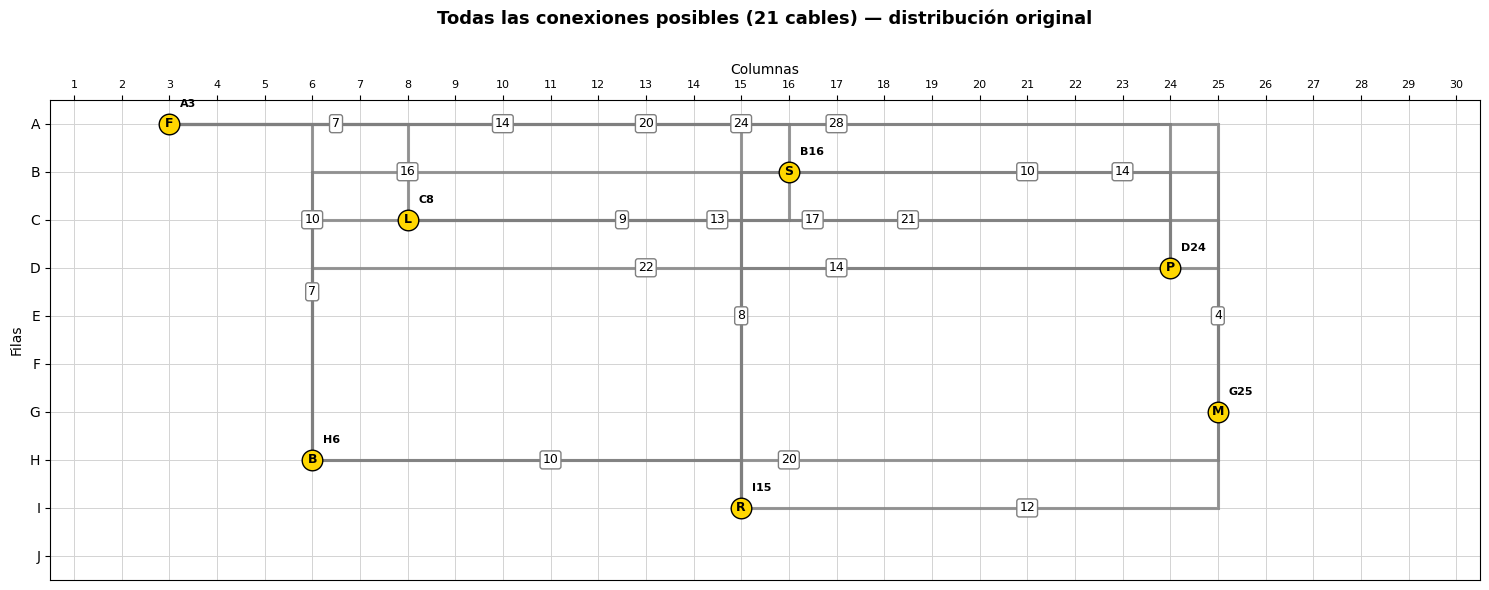

In [13]:
# PUNTOS 2 Y 3
edges_original, mst_original, total_original, record_original = kruskal(initial_components)

print("Ejemplo F-L:", calculate_distance(initial_components["F"], initial_components["L"]))
print()
show_connections(edges_original, "Todas las conexiones posibles — distribución original")

draw_breadboard(initial_components, edges_original,
                title="Todas las conexiones posibles (21 cables) — distribución original",
                wire_color="tab:gray")

### Punto 4 — Árbol de Expansión Mínima (Kruskal)

In [14]:
# PUNTO 4
show_kruskal_record(record_original)
show_mst(mst_original, total_original, "RESULTADO — MST ORIGINAL")

Recorrido de Kruskal (aristas ordenadas por peso):
  P - M =  4  ->  ACEPTADA
  F - L =  7  ->  ACEPTADA
  L - B =  7  ->  ACEPTADA
  S - R =  8  ->  ACEPTADA
  L - S =  9  ->  ACEPTADA
  B - R = 10  ->  descartada (formaría ciclo)
  F - B = 10  ->  descartada (formaría ciclo)
  S - P = 10  ->  ACEPTADA

============ RESULTADO — MST ORIGINAL ============
Cable 1: P - M = 4
Cable 2: F - L = 7
Cable 3: L - B = 7
Cable 4: S - R = 8
Cable 5: L - S = 9
Cable 6: S - P = 10
Cantidad de cables: 6
Longitud total de cable: 45 unidades


### Punto 5 — Visualización del resultado

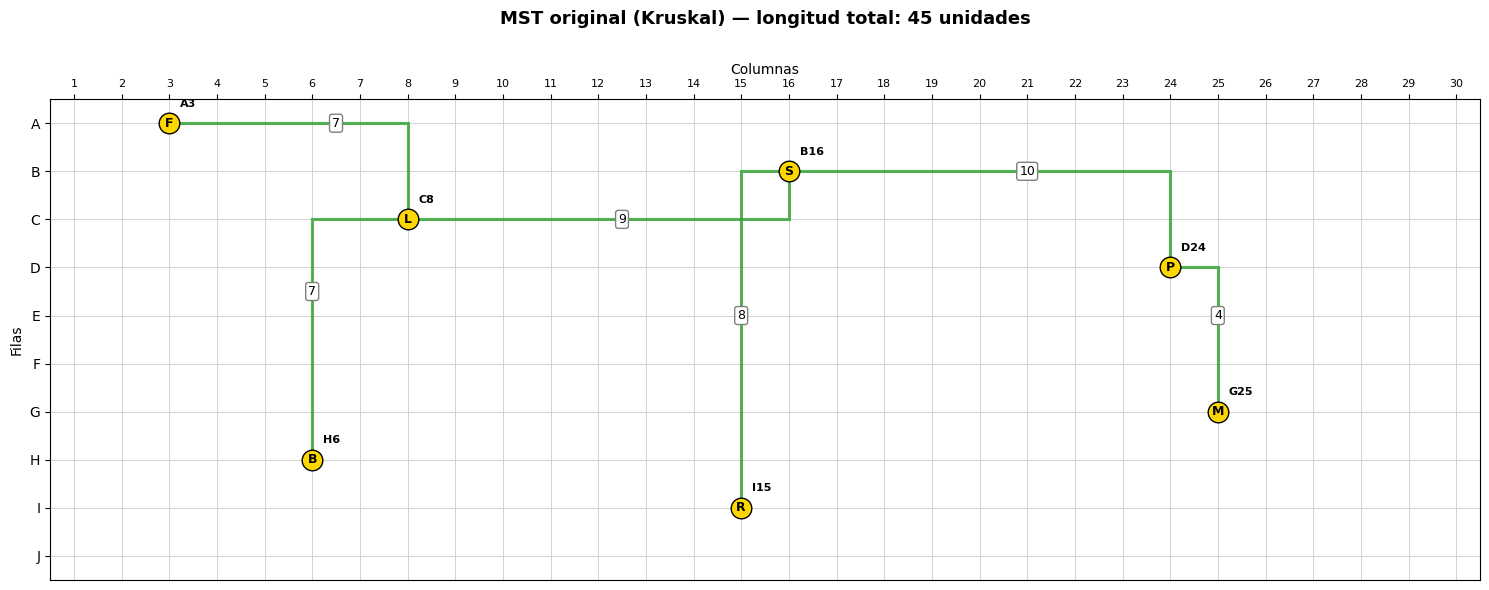

In [15]:
# PUNTO 5
draw_breadboard(initial_components, mst_original,
                title=f"MST original (Kruskal) — longitud total: {total_original} unidades",
                wire_color="tab:green")

### Punto 6 — Cambio en la distribución (Buzzer H6 → J20)

Todas las conexiones posibles — Buzzer en J20
------------------------------------------------
P -------- 4 -------- M
B -------- 6 -------- R
F -------- 7 -------- L
B -------- 8 -------- M
S -------- 8 -------- R
L -------- 9 -------- S
P -------- 10 -------- B
S -------- 10 -------- P
R -------- 12 -------- M
S -------- 12 -------- B
L -------- 13 -------- R
F -------- 14 -------- S
P -------- 14 -------- R
S -------- 14 -------- M
L -------- 17 -------- P
L -------- 19 -------- B
F -------- 20 -------- R
L -------- 21 -------- M
F -------- 24 -------- P
F -------- 26 -------- B
F -------- 28 -------- M
Cantidad de conexiones posibles: 21


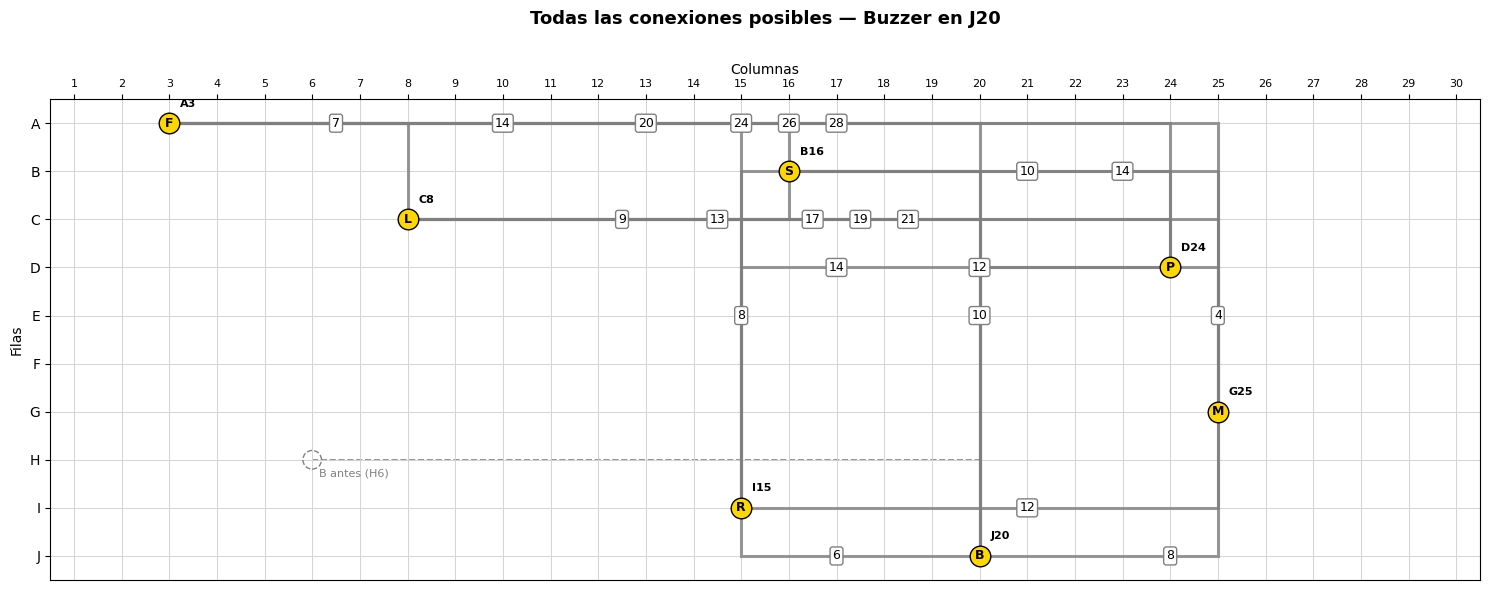

Recorrido de Kruskal (aristas ordenadas por peso):
  P - M =  4  ->  ACEPTADA
  B - R =  6  ->  ACEPTADA
  F - L =  7  ->  ACEPTADA
  B - M =  8  ->  ACEPTADA
  S - R =  8  ->  ACEPTADA
  L - S =  9  ->  ACEPTADA

============ RESULTADO — MST CON BUZZER EN J20 ============
Cable 1: P - M = 4
Cable 2: B - R = 6
Cable 3: F - L = 7
Cable 4: B - M = 8
Cable 5: S - R = 8
Cable 6: L - S = 9
Cantidad de cables: 6
Longitud total de cable: 42 unidades


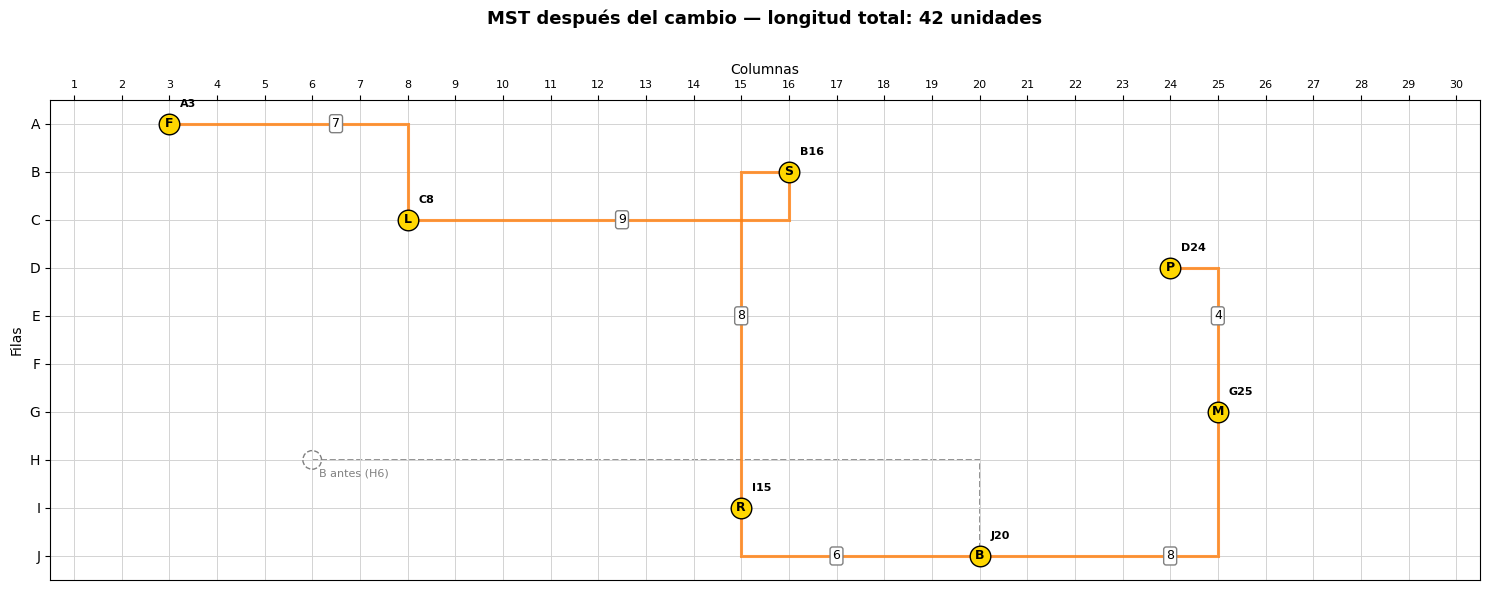

In [16]:
# PUNTO 6
modified_components = move_component(initial_components, "B", "J", 20)
edges_modified, mst_modified, total_modified, record_modified = kruskal(modified_components)

show_connections(edges_modified, "Todas las conexiones posibles — Buzzer en J20")
draw_breadboard(modified_components, edges_modified,
                title="Todas las conexiones posibles — Buzzer en J20",
                wire_color="tab:gray", previous_positions={"B": (6, "H")})

show_kruskal_record(record_modified)
show_mst(mst_modified, total_modified, "RESULTADO — MST CON BUZZER EN J20")

draw_breadboard(modified_components, mst_modified,
                title=f"MST después del cambio — longitud total: {total_modified} unidades",
                wire_color="tab:orange", previous_positions={"B": (6, "H")})

### Comparación final: ¿aumentó o disminuyó el cable?

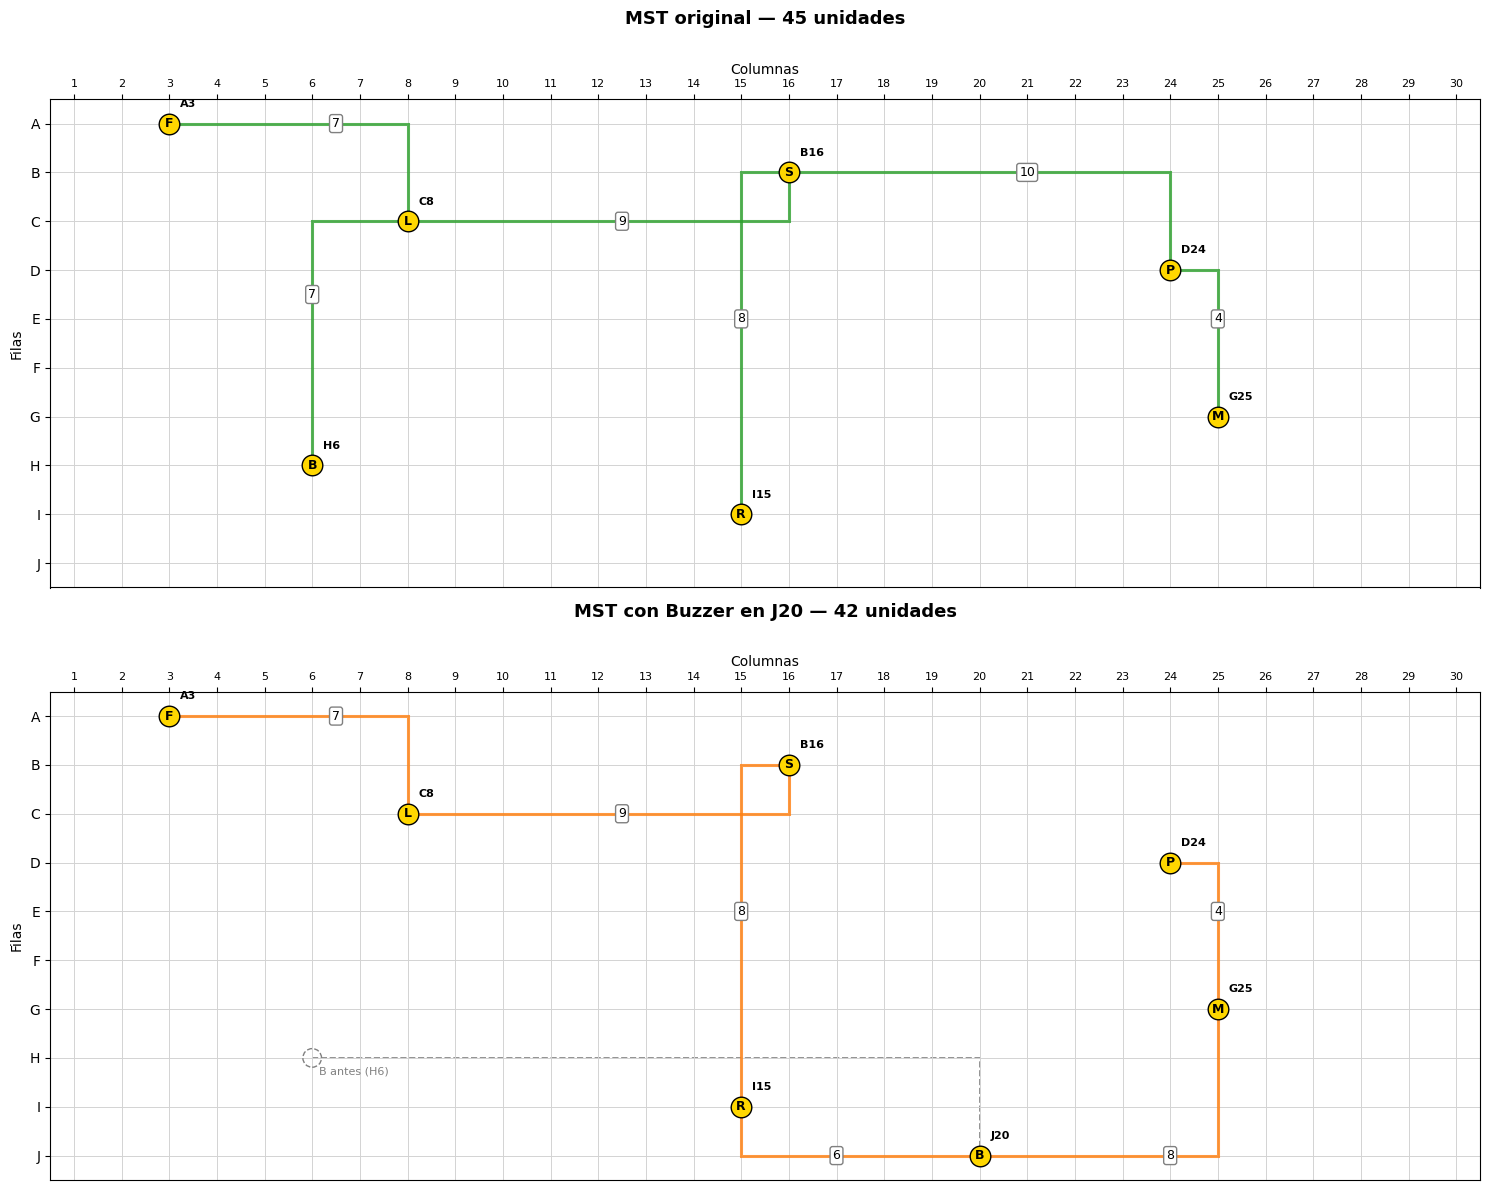

MST original
Longitud total: 45
MST después del cambio
Longitud total: 42
La cantidad de cable DISMINUYÓ en 3 unidades.


In [17]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 12))
draw_breadboard(initial_components, mst_original,
                title=f"MST original — {total_original} unidades",
                ax=ax1, wire_color="tab:green")
draw_breadboard(modified_components, mst_modified,
                title=f"MST con Buzzer en J20 — {total_modified} unidades",
                ax=ax2, wire_color="tab:orange", previous_positions={"B": (6, "H")})
plt.tight_layout()
plt.show()

difference = total_modified - total_original
print("=" * 48)
print("MST original")
print(f"Longitud total: {total_original}")
print("MST después del cambio")
print(f"Longitud total: {total_modified}")
print("=" * 48)
if difference > 0:
    print(f"La cantidad de cable AUMENTÓ en {difference} unidades.")
elif difference < 0:
    print(f"La cantidad de cable DISMINUYÓ en {abs(difference)} unidades.")
else:
    print("La cantidad total de cable NO CAMBIÓ.")

## 7) Tests aplicados **[15 pts]**

Se comprueban los aspectos principales: cantidad de vértices, cantidad de aristas del grafo completo, cantidad de aristas del MST, suma de pesos, cambio de posición del Buzzer y comparación de las longitudes totales.

In [18]:
def is_connected(components, mst):
    neighbors = {k: [] for k in components}
    for _, u, v in mst:
        neighbors[u].append(v)
        neighbors[v].append(u)
    start = next(iter(components))
    visited, stack = {start}, [start]
    while stack:
        current = stack.pop()
        for w in neighbors[current]:
            if w not in visited:
                visited.add(w)
                stack.append(w)
    return len(visited) == len(components)

assert calculate_distance(initial_components["F"], initial_components["L"]) == 7

assert len(initial_components) == 7
assert len(edges_original) == 21
assert len(mst_original) == len(initial_components) - 1
assert is_connected(initial_components, mst_original)
assert sum(weight for weight, _, _ in mst_original) == total_original
assert total_original == 45

assert modified_components["B"]["fila"] == "J"
assert modified_components["B"]["columna"] == 20
assert initial_components["B"]["fila"] == "H"        # el original no se alteró
assert len(edges_modified) == 21
assert len(mst_modified) == len(modified_components) - 1
assert is_connected(modified_components, mst_modified)
assert sum(weight for weight, _, _ in mst_modified) == total_modified
assert total_modified == 42
assert total_modified - total_original == -3

assert all(a in edges_original for a in mst_original)
assert all(a in edges_modified for a in mst_modified)

print("Todas las pruebas fueron superadas correctamente.")
print(f"MST original: {total_original} unidades.")
print(f"MST modificado: {total_modified} unidades.")
print(f"Diferencia: {total_modified - total_original} unidades.")

Todas las pruebas fueron superadas correctamente.
MST original: 45 unidades.
MST modificado: 42 unidades.
Diferencia: -3 unidades.
